# Klasifikasi Biner Data Cuaca (Pendekatan Lanjutan)
Notebook ini difokuskan pada dataset `Weather Test Data.csv`. 

Untuk memberikan variasi dan praktik yang lebih *advanced* dari notebook sebelumnya, kita akan menggunakan pendekatan **Machine Learning Pipeline**, model **Logistic Regression**, dan evaluasi menggunakan **ROC Curve**.


## Kenapa Termasuk Klasifikasi Biner?
Pada dataset cuaca ini, variabel yang menjadi target prediksi adalah **`RainToday`** (Apakah hari ini hujan?).

Walaupun dataset ini memiliki banyak kolom yang berisi nilai kosong (NaN/Missing Values), nilai aktual yang valid pada kolom target `RainToday` hanya terdiri dari dua kategori utama:
1. **'Yes'** (Terjadi Hujan)
2. **'No'** (Tidak Terjadi Hujan)

Karena sistem yang kita rancang bertugas untuk menghasilkan salah satu dari **dua kepastian** tersebut, maka secara konsep ini tetaplah murni **Klasifikasi Biner**.


In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Membaca dataset
df = pd.read_csv('Weather Test Data.csv')
display(df.head())

# Mengecek persentase data yang kosong (Missing Values)
print("\nPersentase Data Kosong tiap Kolom:")
print((df.isnull().sum() / len(df)) * 100)


,row ID,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday
0,Row0,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,26.0,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No
1,Row1,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,9.0,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No
2,Row2,Albury,14.3,25.0,0.0,NaN,NaN,W,50.0,SW,...,24.0,49.0,19.0,1009.6,1008.2,1.0,NaN,18.1,24.6,No
3,Row3,Albury,9.7,31.9,0.0,NaN,NaN,NNW,80.0,SE,...,28.0,42.0,9.0,1008.9,1003.6,NaN,NaN,18.3,30.2,No
4,Row4,Albury,15.9,18.6,15.6,NaN,NaN,W,61.0,NNW,...,28.0,76.0,93.0,994.3,993.0,8.0,8.0,17.4,15.8,Yes



Persentase Data Kosong tiap Kolom:
row ID            0.000000
Location          0.000000
MinTemp           0.454577
MaxTemp           0.215573
Rainfall          1.000539
Evaporation      42.908358
Sunshine         48.032898
WindGustDir       6.582000
WindGustSpeed     6.537479
WindDir9am        7.045950
WindDir3pm        2.647796
WindSpeed9am      0.967734
WindSpeed3pm      1.862830
Humidity9am       1.267662
Humidity3pm       2.586873
Pressure9am       9.996017
Pressure3pm       9.946810
Cloud9am         37.690091
Cloud3pm         40.049675
Temp9am           0.679523
Temp3pm           1.926096
RainToday         1.000539
dtype: float64


## Data Preprocessing (Menggunakan Pipeline)
Berbeda dengan dataset sebelumnya, data cuaca dunia nyata biasanya sangat "kotor" dan penuh dengan data kosong (NaN) akibat sensor cuaca yang rusak atau tidak tercatat. 

Langkah yang kita ambil:
1. Menghapus baris yang nilai targetnya (`RainToday`) kosong, karena kita tidak bisa melatih model tanpa jawaban.
2. Memisahkan kolom numerik dan kategorikal.
3. Membuat **Pipeline Preprocessing**: 
   - *Kolom Numerik*: Mengisi nilai kosong dengan **Median**, lalu menormalkan skala (StandardScaler).
   - *Kolom Kategorikal*: Mengisi nilai kosong dengan kategori paling sering muncul (**Mode**), lalu mengubahnya jadi angka (One-Hot Encoding).


In [12]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# 1. Hapus ID dan baris yang targetnya (RainToday) kosong
if 'row ID' in df.columns:
    df = df.drop(columns=['row ID'])
    
df = df.dropna(subset=['RainToday'])

# Pisahkan Fitur (X) dan Target (y)
X = df.drop(columns=['RainToday'])
y = df['RainToday'].map({'No': 0, 'Yes': 1})

# 2. Definisikan tipe kolom (Diperbarui untuk mengatasi Pandas4Warning)
num_cols = X.select_dtypes(include=['float64', 'int64']).columns
cat_cols = X.select_dtypes(include=['object', 'str']).columns

# 3. Buat Pipeline Imputasi dan Transformasi
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_cols),
    ('cat', cat_transformer, cat_cols)
])

print("Setup Preprocessing Pipeline Selesai tanpa warning!")

Setup Preprocessing Pipeline Selesai tanpa warning!


## Pemodelan dengan Logistic Regression
Kita akan menggunakan algoritma **Regresi Logistik (Logistic Regression)**. Kelebihan algoritma ini adalah dia tidak hanya menebak 'Ya' atau 'Tidak', tapi juga bisa mengeluarkan persentase **probabilitas/peluang** turunnya hujan.


In [13]:
from sklearn.linear_model import LogisticRegression

# Split Data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Gabungkan Preprocessor dan Algoritma ke dalam 1 Pipeline Utama
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

# Latih model
model_pipeline.fit(X_train, y_train)

# Prediksi Kelas (0 atau 1) dan Prediksi Peluang/Probabilitas (%)
y_pred = model_pipeline.predict(X_test)
y_pred_proba = model_pipeline.predict_proba(X_test)[:, 1]

print("Model selesai dilatih melalui Pipeline!")


Model selesai dilatih melalui Pipeline!


## Evaluasi Model (ROC Curve)
Sebagai variasi dari Confusion Matrix, untuk Regresi Logistik sangat ideal jika kita melihat kurva **ROC (Receiver Operating Characteristic)** dan nilai **AUC (Area Under Curve)**. Semakin nilai AUC mendekati 1, semakin pintar model tersebut membedakan hujan dan tidak hujan.


Akurasi Model: 0.99301775147929

Laporan Klasifikasi:
                 precision    recall  f1-score   support

Tidak Hujan (0)       0.99      1.00      1.00      6570
      Hujan (1)       1.00      0.97      0.98      1880

       accuracy                           0.99      8450
      macro avg       1.00      0.98      0.99      8450
   weighted avg       0.99      0.99      0.99      8450



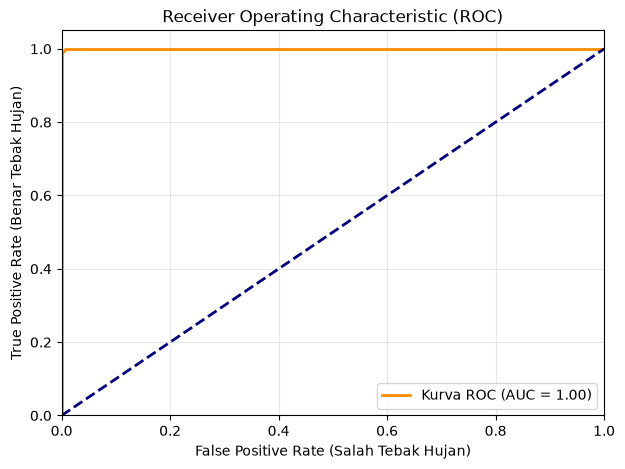

In [14]:
from sklearn.metrics import accuracy_score, classification_report, roc_curve, auc

print("Akurasi Model:", accuracy_score(y_test, y_pred))
print("\nLaporan Klasifikasi:")
print(classification_report(y_test, y_pred, target_names=['Tidak Hujan (0)', 'Hujan (1)']))

# Visualisasi Kurva ROC
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Kurva ROC (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (Salah Tebak Hujan)')
plt.ylabel('True Positive Rate (Benar Tebak Hujan)')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()
